#Classificando caracteres utilizando rede CNN.
Este exemplo utiliza a base de dados MNIST, que consiste em imagens de caracteres numéricos escritos à mão.

##Etapa 01
Importar as bibliotecas de aprendizado de máquina e computação científica.

In [1]:
#Bibliotecas de aprendizado de máquina
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Conv2D
from keras.layers import MaxPooling2D, AveragePooling2D
from keras.layers import Flatten
from keras.layers import Dense
from keras.layers import Dropout
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report


#Bibliotecas de computação científica
import numpy as np
import matplotlib.pyplot as plt

##Etapa 02
Importar a base de dados MNIST do keras

Curiosidade: o Keras fornece um conjunto de base de dados para aprendizado. Veja mais em: https://keras.io/api/datasets/

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

##Etapa 03
Conhecer e plotar a base de dados

In [3]:
#Verificar a quantidade de dados para treinamento e validação
print('x_train', x_train.shape)
print('y_train', y_train.shape)
print('x_test', x_test.shape)
print('y_test', y_test.shape)


x_train (60000, 28, 28)
y_train (60000,)
x_test (10000, 28, 28)
y_test (10000,)


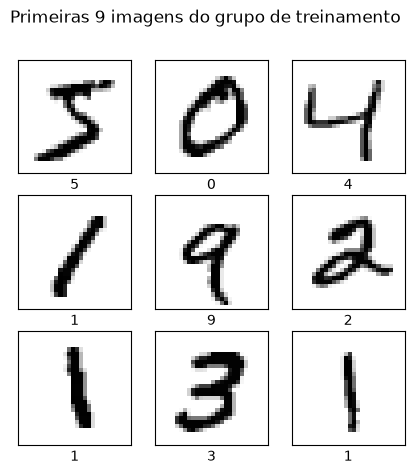

In [4]:
#Plotar imagem
plt.figure(figsize=(5,5))
plt.suptitle('Primeiras 9 imagens do grupo de treinamento')
for i in range(9):
  plt.subplot(3,3,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(x_train[i], cmap=plt.cm.binary)
  plt.xlabel(y_train[i])
plt.show()

In [5]:
x_train[0,:,:]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

In [6]:
y_train

array([5, 0, 4, ..., 5, 6, 8], shape=(60000,), dtype=uint8)

##Etapa 04
Pré-processar as imagens de forma que os valores de intensidade para os pixels fiquem entre 0 e 1.

In [7]:
x_train = x_train/255
x_test = x_test/255

In [8]:
x_train[0,:,:]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [9]:
#y_train = keras.utils.to_categorical(y_train, num_classes=10)
#y_test = keras.utils.to_categorical(y_test, num_classes=10)

##Etapa 05
Construir a rede neural utilizando o Keras.

Primeira camada (entrada): transforma o array bidimensional (28,28) para um array unidimensional (28*28=784).

Segunda camada: Uma camada com 128 neurônios.

Terceira camada (saída): implementa uma softmax de 10 nós que retorna um array de 10 probabilidades, cuja soma resulta em 1. Cada nó contém um valor que indica a probabilidade de que aquela imagem pertença a uma das 10 classes.

In [10]:
keras.backend.clear_session()
model = Sequential()
model.add(Conv2D(64, (3,3), activation='relu', input_shape=(28,28,1))),
model.add(MaxPooling2D(2,2)),
model.add(Dropout(0.3)),
model.add(Conv2D(32, (2,2), activation='relu')),
model.add(MaxPooling2D((2,2))),
model.add(Flatten()),
model.add(Dropout(0.2)),
model.add(Dense(32, activation='relu')),
model.add(Dropout(0.1)),
model.add(Dense(10, activation='softmax'))

model.summary()

c:\Users\leonardo.flores\Desktop\UFOP\CDD109 - REDES NEURAIS ARTIFICIAIS E DEEP LEARNING\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 12, 12, 32)     │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        36,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,090 (180.04 KB)

 Trainable params: 46,090 (180.04 KB)

 Non-trainable params: 0 (0.00 B)

##Etapa 06
Compilar o modelo.

Optimizer: As opções são encontradas em https://keras.io/api/optimizers/

Loss: As opções são encontradas em https://keras.io/api/losses/

Metrics: As opções são encontradas em https://keras.io/api/metrics/

In [11]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_accuracy'])

##Etapa 07
Treinar o modelo e realizar a validação.

Epoch 1/30
500/500 - 14s - 28ms/step - loss: 0.4207 - sparse_categorical_accuracy: 0.8705 - val_loss: 0.0994 - val_sparse_categorical_accuracy: 0.9714
Epoch 2/30
500/500 - 14s - 27ms/step - loss: 0.1425 - sparse_categorical_accuracy: 0.9557 - val_loss: 0.0665 - val_sparse_categorical_accuracy: 0.9785
Epoch 3/30
500/500 - 13s - 26ms/step - loss: 0.1043 - sparse_categorical_accuracy: 0.9683 - val_loss: 0.0504 - val_sparse_categorical_accuracy: 0.9830
Epoch 4/30
500/500 - 15s - 30ms/step - loss: 0.0885 - sparse_categorical_accuracy: 0.9729 - val_loss: 0.0437 - val_sparse_categorical_accuracy: 0.9845
Epoch 5/30
500/500 - 14s - 28ms/step - loss: 0.0762 - sparse_categorical_accuracy: 0.9765 - val_loss: 0.0377 - val_sparse_categorical_accuracy: 0.9879
Epoch 6/30
500/500 - 14s - 28ms/step - loss: 0.0694 - sparse_categorical_accuracy: 0.9791 - val_loss: 0.0368 - val_sparse_categorical_accuracy: 0.9870
Epoch 7/30
500/500 - 14s - 28ms/step - loss: 0.0634 - sparse_categorical_accuracy: 0.9805 - va

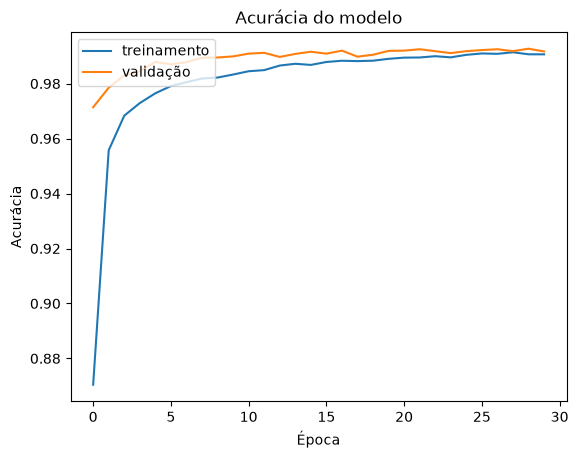

In [12]:
history = model.fit(x_train, y_train, epochs=30, batch_size=120, validation_data=(x_test, y_test), verbose=2)
plt.plot(history.history['sparse_categorical_accuracy'])
plt.plot(history.history['val_sparse_categorical_accuracy'])
plt.title('Acurácia do modelo')
plt.ylabel('Acurácia')
plt.xlabel('Época')
plt.legend(['treinamento', 'validação'], loc='upper left')
plt.show()

##Etapa 08
Realizar algumas predições. Experimente variar a amostra (variável i).

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


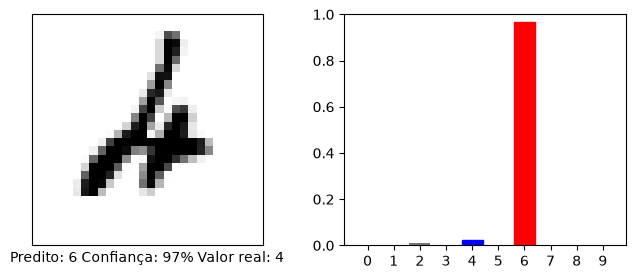

In [13]:
predictions = model.predict(x_test)
class_names = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
i = 247

def plot_image(prediction_array, true_label, img):
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(img, cmap=plt.cm.binary)
  predicted_label = np.argmax(prediction_array)
  plt.xlabel('Predito: {} Confiança: {:2.0f}% Valor real: {}'.format(predicted_label, 100*np.max(prediction_array), true_label))

def plot_rate(prediction_array, true_label):
  plt.grid(False)
  plt.xticks(range(10), class_names)
  thisplot = plt.bar(range(10), prediction_array, color="#777777")
  plt.ylim([0, 1])
  predicted_label = np.argmax(prediction_array)
  thisplot[predicted_label].set_color('red')
  thisplot[true_label].set_color('blue')

plt.figure(figsize=(8,3))
plt.subplot(1,2,1)
plot_image(predictions[i], y_test[i], x_test[i])
plt.subplot(1,2,2)
plot_rate(predictions[i], y_test[i])
plt.show()


In [14]:
print(predictions[247])

[1.1039817e-07 3.4375927e-05 1.1273171e-02 1.9534606e-10 2.2249501e-02
 1.9631200e-06 9.6642214e-01 1.8391482e-12 1.8794251e-05 1.2863156e-11]


##Etapa 09
Encontrar todas as predições erradas.

In [15]:
error_classification = []

for i in range(len(predictions)):
  if (np.argmax(predictions[i]) != y_test[i]):
    error_classification.append(i)

print('Total de predições erradas: ', len(error_classification))
print('Lista das predições erradas: ', error_classification)

Total de predições erradas:  83
Lista das predições erradas:  [247, 340, 359, 445, 449, 582, 625, 659, 938, 947, 1014, 1039, 1112, 1182, 1226, 1232, 1247, 1260, 1393, 1414, 1459, 1530, 1621, 1641, 1681, 1709, 1878, 1901, 1911, 2018, 2035, 2043, 2070, 2118, 2129, 2130, 2135, 2182, 2414, 2454, 2462, 2597, 2654, 2939, 2953, 3030, 3060, 3225, 3289, 3422, 3503, 3520, 3662, 3727, 3778, 3808, 4176, 4207, 4284, 4369, 4500, 4536, 4740, 4763, 4807, 4823, 4956, 5600, 5623, 5937, 5955, 5997, 6555, 6597, 6625, 6755, 9009, 9015, 9587, 9642, 9692, 9729, 9770]


In [16]:
x_test[1].shape

(28, 28)

#Informação complementar
##Realizar a predição de uma única imagem

Na Etapa 08, realizamos a predição de todas as amostras de validação e plotamos o resultado de uma única amostra para visualização, isso porque o Keras é otimizado para trabalhar com batch (coleções) de dados. Para realizar a predição de uma única imagem, os passos abaixo são necessários.

In [17]:
#Escolha da imagem
img_selected = 321
img = x_test[img_selected]
print(img.shape)


(28, 28)


Como o Keras trabalha com batch, é preciso adicionar a imagem desejada em uma lista cujo único elemento seja a imagem que se deseja predizer. Para isso, basta expandir as dimensões da imagem para 3, sendo o primeiro elemento a posição na lista.

In [18]:
#reshape
img = (np.expand_dims(img,0))
print(img.shape)

(1, 28, 28)


Com a única imagem na lista, é possível realizar a sua predição.

In [19]:
value_predicted = model.predict(img)
print(value_predicted)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
[[2.8383073e-07 3.5992110e-05 8.3518749e-01 6.0592126e-04 1.1350345e-09
  1.2659422e-09 1.2524949e-13 1.6131179e-01 2.8580436e-03 4.9344806e-07]]


Por fim, encontramos a maior probabilidade e exibimos o resultado, como na Etapa 08

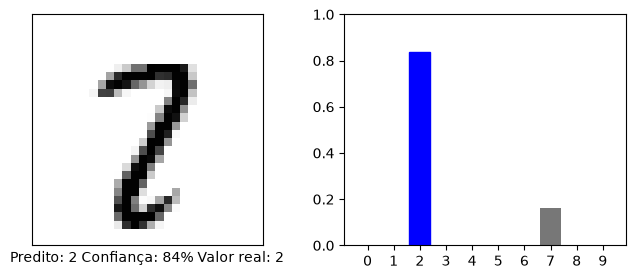

In [20]:
plt.figure(figsize=(8,3))
plt.subplot(1,2,1)
plot_image(value_predicted, y_test[img_selected], x_test[img_selected])
plt.subplot(1,2,2)
plot_rate(value_predicted[0], y_test[img_selected])
plt.show()

#Análise das métricas

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


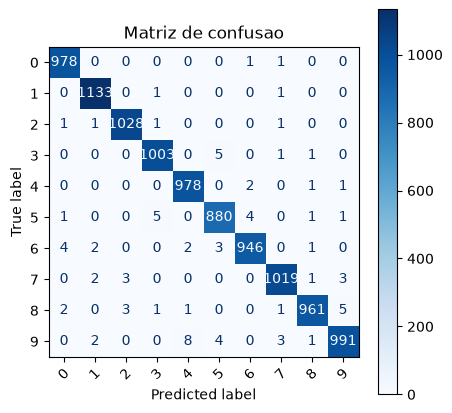

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      1.00      1.00      1032
           3       0.99      0.99      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [21]:
y_pred_prob = model.predict(x_test)

# Converte as probabilidades em classes discretas (0, 1, 2, ..., 9)
y_pred = np.argmax(y_pred_prob, axis=1)

# Matriz de confusao (linhas = classe real, colunas = classe prevista)

cm = confusion_matrix(y_test, y_pred, labels=range(10))

fig, ax = plt.subplots(figsize=(5, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=class_names)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45)
plt.title('Matriz de confusao')
plt.show()

# Precisao, recall e F1 por classe (convertendo class_names para strings para evitar o erro de len)
print(classification_report(y_test, y_pred, labels=range(10), target_names=[str(x) for x in class_names], zero_division=0))